# Лабораторная работа 5. Автоэнкодер без меток
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

Обучите автоэнкодер восстанавливать входные изображения, сравните его со средним
обучающим изображением и найдите соседей по представлениям кодировщика.
Ячейки содержат весь код. Нужны PyTorch и два gzip-файла изображений Fashion-MNIST.

## 1. Вход и цель
Целевое значение здесь — само изображение $x$, а выход — его реконструкция $\widehat x$.
Потери равны среднему квадрату разности по всем изображениям и пикселям.
Кодировщик переводит 784 пикселя в 16 признаков, декодировщик возвращает 784 значения.
Метки классов не загружаются.

In [1]:
"""Автоэнкодер Fashion-MNIST и поиск соседей без загрузки меток."""

from copy import deepcopy
import gzip
from hashlib import md5
from pathlib import Path
import struct
from urllib.request import urlopen

import torch
from torch import nn
from torch.utils.data import DataLoader


SOURCE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CHECKSUMS = {
    "train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
    "t10k-images-idx3-ubyte.gz": "bef4ecab320f06d8554ea6380940ec79",
}


def download_images(folder):
    folder.mkdir(parents=True, exist_ok=True)
    for name, expected in CHECKSUMS.items():
        target = folder / name
        if target.is_file() and md5(target.read_bytes()).hexdigest() == expected:
            continue
        with urlopen(SOURCE + name, timeout=60) as response:
            contents = response.read()
        if md5(contents).hexdigest() != expected:
            raise ValueError(f"Контрольная сумма не совпала: {name}")
        target.write_bytes(contents)


def read_images(folder, prefix, count):
    name = f"{prefix}-images-idx3-ubyte.gz"
    with gzip.open(folder / name, "rb") as stream:
        header = struct.unpack(">IIII", stream.read(16))
        pixels = bytearray(stream.read())
    if header != (2051, count, 28, 28) or len(pixels) != count * 784:
        raise ValueError(f"Некорректный формат или размер IDX: {name}")
    images = torch.frombuffer(pixels, dtype=torch.uint8).reshape(count, 784)
    return images.float().div_(255)


def load_images(folder, seed):
    source = read_images(folder, "train", 60000)
    order = torch.randperm(len(source), generator=torch.Generator().manual_seed(seed))
    test = read_images(folder, "t10k", 10000)
    return source[order[:55000]], source[order[55000:]], test


class Autoencoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


@torch.no_grad()
def pixel_mse(model, loader, device):
    model.eval()
    squares, count = 0.0, 0
    for images in loader:
        images = images.to(device)
        squares += (model(images) - images).square().sum().item()
        count += images.numel()
    return squares / count


@torch.no_grad()
def mean_image_mse(train, loader, device):
    mean_image = train.mean(dim=0).to(device)
    squares, count = 0.0, 0
    for images in loader:
        images = images.to(device)
        squares += (mean_image - images).square().sum().item()
        count += images.numel()
    return squares / count


def fit(model, train_loader, val_loader, device, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    best_epoch, best_mse = 0, float("inf")
    for epoch in range(1, epochs + 1):
        model.train()
        squares, count = 0.0, 0
        for images in train_loader:
            images = images.to(device)
            optimizer.zero_grad()
            loss = (model(images) - images).square().mean()
            loss.backward()
            optimizer.step()
            squares += loss.item() * images.numel()
            count += images.numel()
        val_mse = pixel_mse(model, val_loader, device)
        print(f"epoch={epoch} train_mse={squares / count:.6f} val_mse={val_mse:.6f}")
        if val_mse < best_mse:
            best_epoch, best_mse = epoch, val_mse
            best_weights = deepcopy(model.state_dict())
    model.load_state_dict(best_weights)
    return best_epoch, best_mse


@torch.no_grad()
def encode(model, loader, device):
    model.eval()
    return torch.cat([model.encoder(images.to(device)).cpu() for images in loader])


def nearest_neighbors(embeddings, query_index, k=5):
    if not 0 <= query_index < len(embeddings) or not 0 < k < len(embeddings):
        raise ValueError("Нужны индекс из галереи и 1 ≤ k < числа объектов")
    squared = (embeddings - embeddings[query_index]).square().sum(dim=1)
    # Убираем из поиска объект с тем же индексом. Остальные строки остаются.
    squared[query_index] = float("inf")
    order = torch.argsort(squared, stable=True)[:k]
    return order, squared[order].sqrt()

## 2. Короткая проверка
Укажите DATA_DIR либо задайте переменную FASHION_MNIST_DIR до запуска ядра.
При необходимости переключите DOWNLOAD. Этот опыт берёт 4096 тренировочных
и 1024 валидационных изображения из отдельных частей официальной обучающей выборки.
Тестовые изображения в коротком опыте не оцениваются.

In [2]:
import os

DATA_DIR = Path(os.environ.get("FASHION_MNIST_DIR", "fashion_mnist_data"))
DOWNLOAD = False
DEVICE = "cpu"  # При доступной CUDA можно выбрать "cuda".
SEED = 42
EPOCHS = 1
BATCH_SIZE = 256
LATENT_DIM = 16
if DOWNLOAD:
    download_images(DATA_DIR)
if any(not (DATA_DIR / name).is_file() for name in CHECKSUMS):
    raise FileNotFoundError("Укажите DATA_DIR с изображениями или включите DOWNLOAD.")

torch.set_num_threads(2)
torch.manual_seed(SEED)
train_full, val_full, test = load_images(DATA_DIR, SEED)
train, val = train_full[:4096], val_full[:1024]
train_loader = DataLoader(
    train, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(val, batch_size=BATCH_SIZE)
model = Autoencoder(latent_dim=LATENT_DIM).to(DEVICE)
probe = val[:2].to(DEVICE)
assert model.encoder(probe).shape == (2, LATENT_DIM)
assert model(probe).shape == (2, 784)
print(f"train={len(train)} val={len(val)} epochs={EPOCHS} batch={BATCH_SIZE}")
print("Параметров:", sum(p.numel() for p in model.parameters()))
print(f"PyTorch {torch.__version__} | {DEVICE} | seed={SEED}")

train=4096 val=1024 epochs=1 batch=256
Параметров: 205856
PyTorch 2.10.0+cpu | cpu | seed=42


In [3]:
best_epoch, best_mse = fit(model, train_loader, val_loader, DEVICE, EPOCHS)
mean_mse = mean_image_mse(train, val_loader, DEVICE)
print(f"best_epoch={best_epoch} val_mse={best_mse:.6f}")
print(f"mean_image_val_mse={mean_mse:.6f}")
print(f"Относительное снижение MSE: {100*(1-best_mse/mean_mse):.2f}%")

epoch=1 train_mse=0.140079 val_mse=0.100793
best_epoch=1 val_mse=0.100793
mean_image_val_mse=0.087388
Относительное снижение MSE: -15.34%


## 3. Сравнение изображений
Слева показан вход. Средний столбец один и тот же для всех входов.
Справа результат автоэнкодера. Сопоставьте исчезнувшие мелкие детали
со средним значением ошибки, которое агрегируется по всем изображениям.

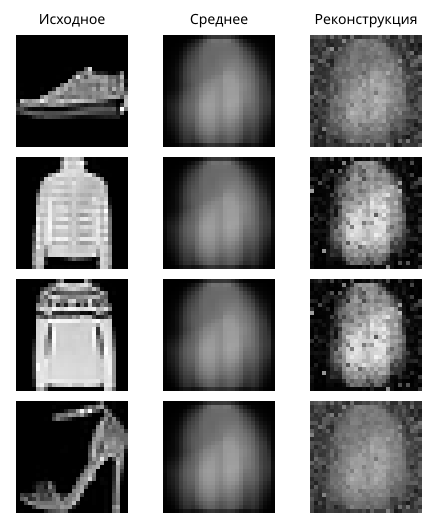

In [4]:
import base64
import zlib
from IPython.display import SVG, display

def grayscale_png(flat):
    pixels = flat.reshape(28, 28).clamp(0, 1).mul(255).round().to(torch.uint8)
    scanlines = b"".join(b"\0" + bytes(row) for row in pixels.tolist())

    def chunk(kind, body):
        checksum = zlib.crc32(kind + body) & 0xFFFFFFFF
        return struct.pack(">I", len(body)) + kind + body + struct.pack(">I", checksum)

    header = struct.pack(">IIBBBBB", 28, 28, 8, 0, 0, 0, 0)
    png = b"\x89PNG\r\n\x1a\n"
    png += chunk(b"IHDR", header) + chunk(b"IDAT", zlib.compress(scanlines))
    png += chunk(b"IEND", b"")
    return base64.b64encode(png).decode("ascii")

def image_panel(flat, x, y, size):
    uri = "data:image/png;base64," + grayscale_png(flat)
    return (f'<image x="{x}" y="{y}" width="{size}" height="{size}" '
            f'style="image-rendering:pixelated" xlink:href="{uri}"/>')

def show_grid(width, height, title, parts):
    svg = (
        '<svg xmlns="http://www.w3.org/2000/svg" '
        'xmlns:xlink="http://www.w3.org/1999/xlink" '
        f'width="{width}" height="{height}" viewBox="0 0 {width} {height}" '
        f'role="img" aria-label="{title}" font-family="sans-serif" font-size="14">'
        f'<rect width="{width}" height="{height}" fill="white"/>'
        + "".join(parts) + "</svg>"
    )
    display(SVG(svg))

chosen = val[:4]
model.eval()
with torch.no_grad():
    restored = model(chosen.to(DEVICE)).cpu()
mean = train.mean(dim=0)
parts = []
for x, label in zip((72, 219, 366), ("Исходное", "Среднее", "Реконструкция")):
    parts.append(f'<text x="{x}" y="24" text-anchor="middle">{label}</text>')
for i in range(len(chosen)):
    y = 35 + i * 122
    for x, image in zip((16, 163, 310), (chosen[i], mean, restored[i])):
        parts.append(image_panel(image, x, y, 112))
show_grid(440, 530, "Сравнение оригиналов среднего изображения и реконструкций", parts)

## 4. Соседи по коду
Галерея — 1024 валидационных изображения. Сравните код выбранного запроса
с кодами галереи. Индекс запроса исключается перед сортировкой расстояний.
Классы в этом поиске не используются.

Форма кодов: (1024, 16)
Индексы соседей: [109, 480, 539, 187, 283]
Расстояния: [0.173855, 0.181673, 0.195046, 0.21444, 0.26589]


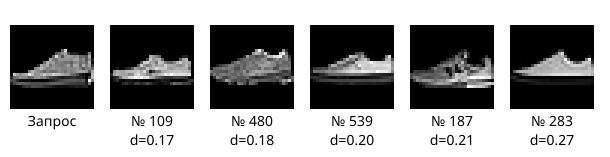

In [5]:
QUERY_INDEX = 0
gallery = val[:1024]
gallery_loader = DataLoader(gallery, batch_size=BATCH_SIZE)
codes = encode(model, gallery_loader, DEVICE)
neighbors, distances = nearest_neighbors(codes, QUERY_INDEX, k=5)
assert codes.shape == (len(gallery), LATENT_DIM) and QUERY_INDEX not in neighbors.tolist()
print("Форма кодов:", tuple(codes.shape))
print("Индексы соседей:", neighbors.tolist())
print("Расстояния:", [round(d, 6) for d in distances.tolist()])

parts = [image_panel(gallery[QUERY_INDEX], 10, 25, 84),
         '<text x="52" y="126" text-anchor="middle">Запрос</text>']
for position, (index, distance) in enumerate(zip(neighbors.tolist(), distances.tolist()), start=1):
    x = 10 + position * 100
    parts.append(image_panel(gallery[index], x, 25, 84))
    parts.append(f'<text x="{x+42}" y="126" text-anchor="middle">№ {index}</text>')
    parts.append(f'<text x="{x+42}" y="145" text-anchor="middle">d={distance:.2f}</text>')
show_grid(610, 157, "Запрос и пять ближайших соседей в пространстве кодов", parts)

## 5. Самостоятельная работа
**A.** Рассчитайте MSE для пары из трёх пикселей и проверьте число параметров.
Сравните четыре реконструкции со средним изображением.

**B.** Повторите короткий опыт с 4 и 32 признаками в коде при том же разбиении.
Сравните MSE на валидации и сохранность деталей. Выберите размер по валидации.

**C.** Проверьте несколько запросов и сравните соседей в пространстве пикселей
и в пространстве кодов. Оцените выбранную конфигурацию на тесте после завершения
отбора. Объясните, какие сходства доступны без разметки.

Данные: [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).